# 13.1 Calculus source audit

Inspect the immutable public source archive and its annotation schema before training. The original test images remain unopened.

In [1]:
from pathlib import Path
import hashlib, zipfile
root = Path.cwd()
while not (root / "pyproject.toml").exists():
    root = root.parent
archive = root / "data/raw/calculus_singh868/multi-class-oral-disease-detection-dataset.zip"
sha256 = hashlib.file_digest(archive.open("rb"), "sha256").hexdigest()
print("Archive:", archive.name, "\nBytes:", archive.stat().st_size, "\nSHA-256:", sha256)

Archive: multi-class-oral-disease-detection-dataset.zip 
Bytes: 292869544 
SHA-256: a85da694d304d3f53c85421b201fad49a3cb6661b639ad05374d341d41f460ca


## Archive structure and original class map

Inspect metadata only. Class indices must be read from the dataset rather than inferred.

In [2]:
with zipfile.ZipFile(archive) as z:
    names = z.namelist()
    print("Archive entries:", len(names))
    yaml_files = [name for name in names if name.endswith("data.yaml")]
    for name in yaml_files:
        print("\n", name, "\n", z.read(name).decode("utf-8"))
    for split in ("train", "valid", "test"):
        print(split, "images:", sum(f"/{split}/images/" in name.lower() and name.lower().endswith((".jpg", ".jpeg", ".png")) for name in names))

Archive entries: 17233

 oral_dataset/data.yaml 
 
train: ../train/images
val: ../valid/images
test: ../test/images

nc: 5

names:
  0: calculus
  1: cancer
  2: caries
  3: gingivitis
  4: ulcer

train images: 6029
valid images: 1720
test images: 867


## Training and validation annotation inventory

Count source labels, malformed rows and image-label pairing. The test set remains unopened. A missing label is recorded as unknown.

In [3]:
from collections import Counter
from pathlib import PurePosixPath
import math
counts = Counter()
with zipfile.ZipFile(archive) as z:
    files = set(z.namelist())
    for split in ("train", "valid"):
        images = [x for x in files if f"/{split}/images/" in x.lower() and x.lower().endswith((".jpg", ".jpeg", ".png"))]
        for image in images:
            label = image.replace("/images/", "/labels/").rsplit(".", 1)[0] + ".txt"
            counts[(split, "images")] += 1
            if label not in files:
                counts[(split, "missing_label")] += 1
                continue
            rows = z.read(label).decode("utf-8-sig").splitlines()
            has_calculus = False
            for row in rows:
                try:
                    v = [float(x) for x in row.split()]
                    if len(v) != 5 or not all(math.isfinite(x) for x in v) or v[0] not in range(5) or not all(0 <= x <= 1 for x in v[1:]) or v[3] <= 0 or v[4] <= 0: raise ValueError()
                    counts[(split, f"class_{int(v[0])}_boxes")] += 1
                    has_calculus |= v[0] == 0
                except ValueError:
                    counts[(split, "invalid_rows")] += 1
            counts[(split, "calculus_images")] += has_calculus
for key, value in sorted(counts.items()): print(key, value)

('train', 'calculus_images') 846
('train', 'class_0_boxes') 5898
('train', 'class_1_boxes') 1916
('train', 'class_2_boxes') 5513
('train', 'class_3_boxes') 11672
('train', 'class_4_boxes') 2128
('train', 'images') 6029
('train', 'invalid_rows') 2
('valid', 'calculus_images') 241
('valid', 'class_0_boxes') 1513
('valid', 'class_1_boxes') 561
('valid', 'class_2_boxes') 1554
('valid', 'class_3_boxes') 3206
('valid', 'class_4_boxes') 647
('valid', 'images') 1720


## Visual review of calculus boxes

Display a deterministic sample of training images and the source class 0 boxes. This gallery supports schema inspection; it does not validate every label.

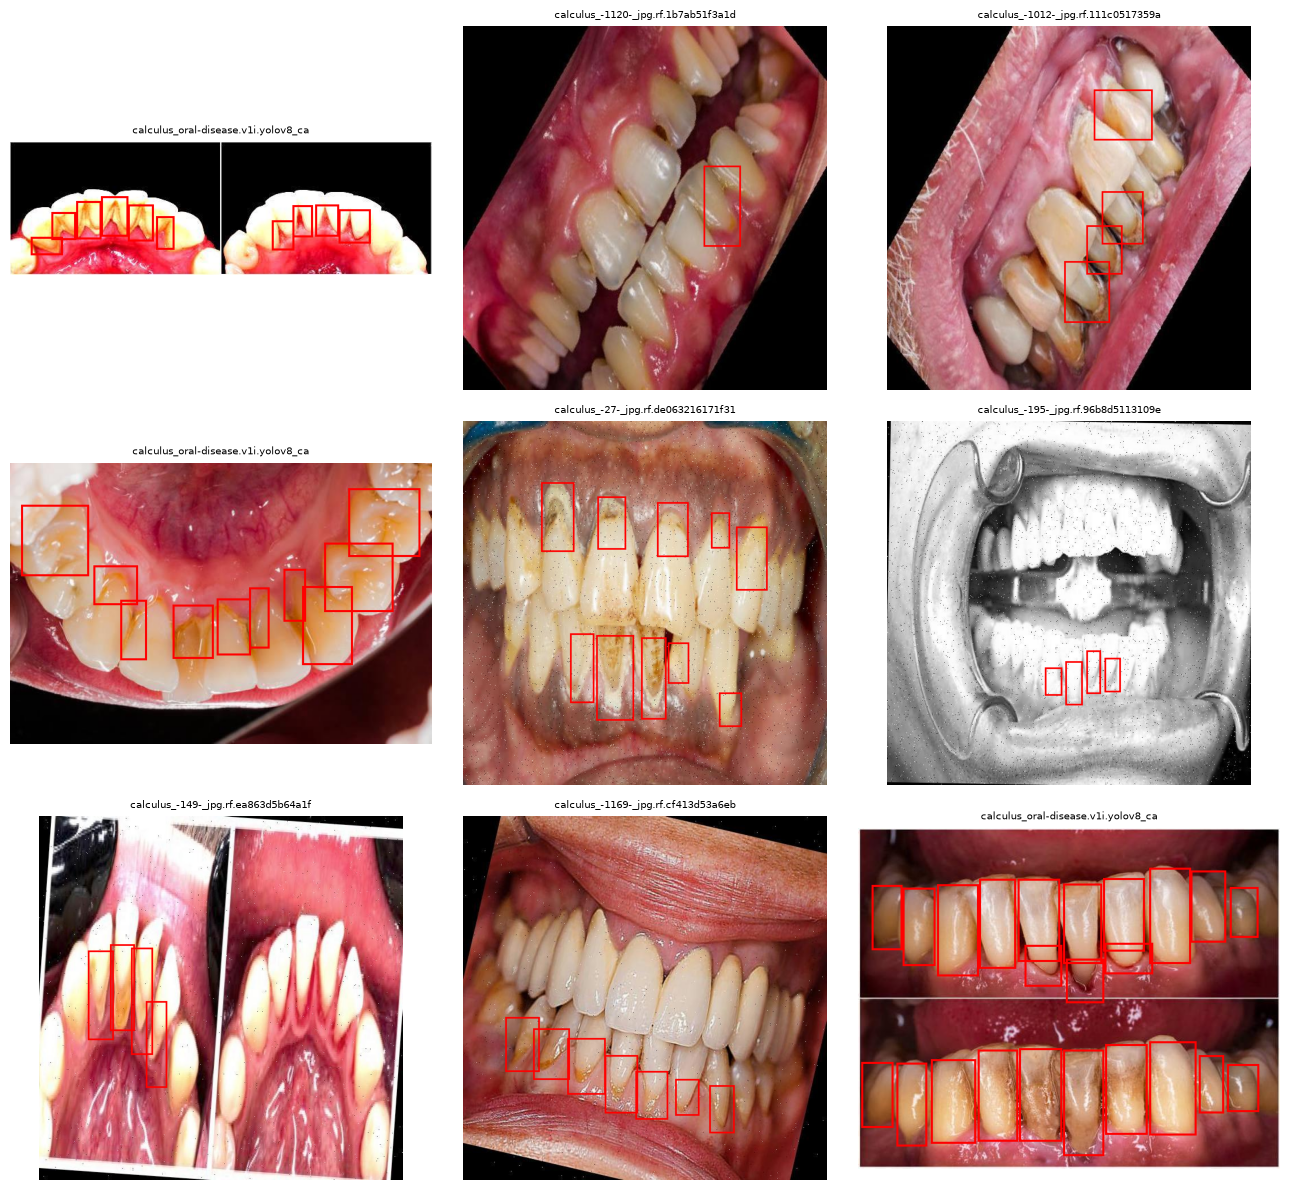

In [4]:
import io, random
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
with zipfile.ZipFile(archive) as z:
    names = sorted(x for x in z.namelist() if "/train/labels/" in x and x.endswith(".txt"))
    eligible = [x for x in names if any(line.split() and line.split()[0] == "0" for line in z.read(x).decode("utf-8-sig").splitlines())]
    sample = random.Random(42).sample(eligible, min(9, len(eligible)))
    fig, axes = plt.subplots(3, 3, figsize=(13, 12))
    for ax, label in zip(axes.flat, sample):
        stem = label.replace("/labels/", "/images/").rsplit(".", 1)[0]
        image_name = next((stem + ext for ext in (".jpg", ".jpeg", ".png", ".JPG") if stem + ext in z.namelist()), None)
        if image_name is None:
            ax.set_title("Missing image"); ax.axis("off"); continue
        im = Image.open(io.BytesIO(z.read(image_name))).convert("RGB")
        draw = ImageDraw.Draw(im)
        for line in z.read(label).decode("utf-8-sig").splitlines():
            parts = line.split()
            if len(parts) != 5 or parts[0] != "0": continue
            cx, cy, w, h = map(float, parts[1:])
            draw.rectangle(((cx-w/2)*im.width, (cy-h/2)*im.height, (cx+w/2)*im.width, (cy+h/2)*im.height), outline="red", width=max(2, im.width//200))
        ax.imshow(im); ax.set_title(PurePosixPath(image_name).name[:35], fontsize=7); ax.axis("off")
    plt.tight_layout(); plt.show()

## Invalid training annotations

Record the exact invalid rows. Both have class 1 (cancer) and zero width or height. Preserve the originals and quarantine affected images if building a training set.

In [5]:
with zipfile.ZipFile(archive) as z:
    for name in sorted(x for x in z.namelist() if "/train/labels/" in x and x.endswith(".txt")):
        for line_number, line in enumerate(z.read(name).decode("utf-8-sig").splitlines(), 1):
            try:
                values = [float(x) for x in line.split()]
                if len(values) != 5 or not all(math.isfinite(x) for x in values) or values[0] not in range(5) or not all(0 <= x <= 1 for x in values[1:]) or values[3] <= 0 or values[4] <= 0:
                    raise ValueError()
            except ValueError:
                print(name, "line", line_number, repr(line))

oral_dataset/train/labels/cancer_Oral Spot Detection V3 OP.v2-v3-ops.yolov8_cancer-1212-_jpg.rf.ed7cfdfcd65b9e7c217d59d0e847384a.txt line 1 '1 0.44744788281250003 0 0 0.0951079828125'
oral_dataset/train/labels/cancer_Oral Spot Detection V3 OP.v2-v3-ops.yolov8_cancer-50-_jpg.rf.c35124abd9c549b283880dc3924cf0c9.txt line 1 '1 0.5705882359375 0.007374631249999999 0.4843137265625 0'
